In [8]:
import numpy as np
import scipy as sc
import math
import matplotlib.pyplot as plt

In [6]:
# step 1 cuz this too much
T = 720 # hours -> 30 days
lambd_max = 20

def lambd_true(t):
    return 12 + 8*np.cos(np.pi * (t-16)/12)

N_prop = np.random.poisson(lambd_max * T)
times_prop = np.sort(np.random.uniform(0,T, size=N_prop))
accept = lambd_true(times_prop) / lambd_max
mask = np.random.uniform(0,1, size=N_prop) < accept
times_keep = times_prop[mask]

N_keep = len(times_keep)
fraction_keep = N_keep/N_prop
print(f'Fraction Kept: {fraction_keep} ')

Fraction Kept: 0.6005741090807253 


Text(0.5, 1.0, 'Emergency Room Arrival Per Hour Simulated vs True')

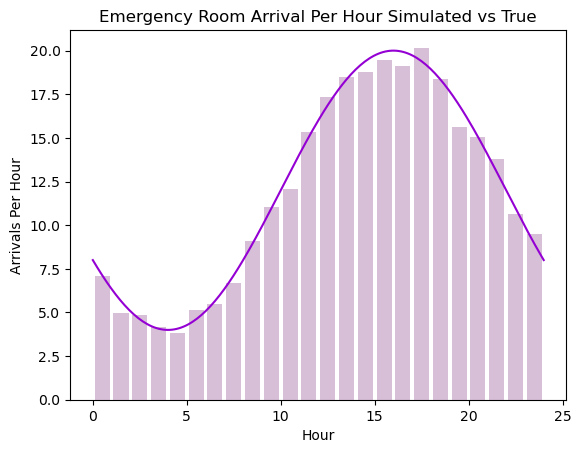

In [15]:
# step 2 NEXT

# consider 30 days with 24 hours each so that then we can sum them up
counts_hr = np.zeros((30,24))

# use the kept times from above cuz we lazy
for t in times_keep:
    day = math.floor(t/24)
    hour = int(t % 24)
    counts_hr[day, hour] += 1

mean_hr = np.mean(counts_hr, axis=0)

t_times = np.linspace(0,24,200)

# hehe fun colors
plt.bar(np.arange(24)+0.5, mean_hr, color='thistle', label='Simulated Daily Hourly Mean')
plt.plot(t_times, lambd_true(t_times), color='darkviolet', label='True $\\lambda(t)$')
plt.xlabel('Hour')
plt.ylabel('Arrivals Per Hour')
plt.title('Emergency Room Arrival Per Hour Simulated vs True')

In [17]:
# step 3 - you know this should be part c
# so we already have the counts:

counts_34 = counts_hr[:,3]
mean_34 = np.mean(counts_34)
var_34 = np.var(counts_34)
print(f'Simulated Mean: {mean_34}')
print(f'Simulated Variance: {var_34}')

Simulated Mean: 4.166666666666667
Simulated Variance: 4.205555555555555


In [20]:
# step 4 log-likelihood jazz
n = len(times_keep)

def log_likelihood(params, t_events, T):
    a = params[0]
    b = params[1]
    phi = params[2]
    rate = a+ b * np.cos(np.pi * (t_events - phi)/12)
    Lambd = a * T
    ll = np.sum(np.log(rate)) - Lambd
    return -ll

a0 = 10
b0 = 5
phi0 = 14

# apparently there is no maximize function so I guess we will minimzie the negative cuz why not
result = sc.optimize.minimize(log_likelihood, [a0, b0, phi0], args=(times_keep, T))

ahat = result.x[0]
bhat = result.x[1]
phihat = result.x[2]
max_ll_fitted = - result.fun

lambd_const = n / T
ll_const = n * np.log(lambd_const) - lambd_const * T

#--------print everything-----------------
print(f'a: {ahat}')
print(f'b: {bhat}')
print(f'phi: {phihat}')
print()
print(f'fitted log-likelihood: {max_ll_fitted}')
print(f'constant rate log-likelihood: {ll_const}')
print(f'difference: {max_ll_fitted - ll_const}')

a: 11.913888621857645
b: 7.946449495970469
phi: 16.00282083641376

fitted log-likelihood: 13692.091362850048
constant rate log-likelihood: 12675.752229606365
difference: 1016.3391332436822
